# Student Academic Result Analysis System
## How the project works

**Registration:** AP26122050024  
This notebook explains only the result calculation and comparison. The desktop and website interfaces use the same grading rules.

### 1. Calculate one result
Each subject is out of 100. A student needs at least 40 in every subject to pass.

In [1]:
SUBJECTS = ("Python", "Algorithms", "Network Security", "Database")

def calculate_result(marks):
    for subject in SUBJECTS:
        if not 0 <= marks[subject] <= 100:
            raise ValueError(f"{subject} must be between 0 and 100")

    total = sum(marks.values())
    percentage = total / 4

    if any(mark < 40 for mark in marks.values()):
        return total, percentage, "F", "Fail"

    if percentage >= 90:
        grade = "A+"
    elif percentage >= 80:
        grade = "A"
    elif percentage >= 70:
        grade = "B"
    elif percentage >= 60:
        grade = "C"
    else:
        grade = "D"
    return total, percentage, grade, "Pass"

print("Result function is ready.")


Result function is ready.


### 2. Enter three example students
These marks are illustrative and are not official academic records.

In [2]:
students = {
    "AP26122050024": {"Python": 82, "Algorithms": 76, "Network Security": 91, "Database": 65},
    "DEMO_A": {"Python": 92, "Algorithms": 88, "Network Security": 94, "Database": 90},
    "DEMO_B": {"Python": 78, "Algorithms": 72, "Network Security": 35, "Database": 85},
}

print("Example students:", len(students))


Example students: 3


### 3. Show each result
The total, percentage, grade, and pass/fail status come from the same function.

In [3]:
results = {}
for registration, marks in students.items():
    results[registration] = calculate_result(marks)
    total, percentage, grade, status = results[registration]
    print(f"{registration}: {total}/400 | {percentage:.1f}% | {grade} | {status}")


AP26122050024: 314/400 | 78.5% | B | Pass
DEMO_A: 364/400 | 91.0% | A+ | Pass
DEMO_B: 270/400 | 67.5% | F | Fail


### 4. Compare the class
Sort by percentage, then calculate the class average and pass rate. A percentage alone does not decide pass/fail.

In [4]:
ranked = sorted(results.items(), key=lambda item: item[1][1], reverse=True)

print("Ranking:")
for position, (registration, result) in enumerate(ranked, start=1):
    print(f"{position}. {registration}: {result[1]:.1f}% ({result[3]})")

class_average = sum(result[1] for result in results.values()) / len(results)
pass_rate = sum(result[3] == "Pass" for result in results.values()) / len(results) * 100
print(f"Class average: {class_average:.1f}%")
print(f"Pass rate: {pass_rate:.1f}%")
print("DEMO_B fails because Network Security is 35, below 40.")


Ranking:
1. DEMO_A: 91.0% (Pass)
2. AP26122050024: 78.5% (Pass)
3. DEMO_B: 67.5% (Fail)
Class average: 79.0%
Pass rate: 66.7%
DEMO_B fails because Network Security is 35, below 40.


### 5. Draw the comparison chart
The bars show percentages; gray marks the student who failed a subject.

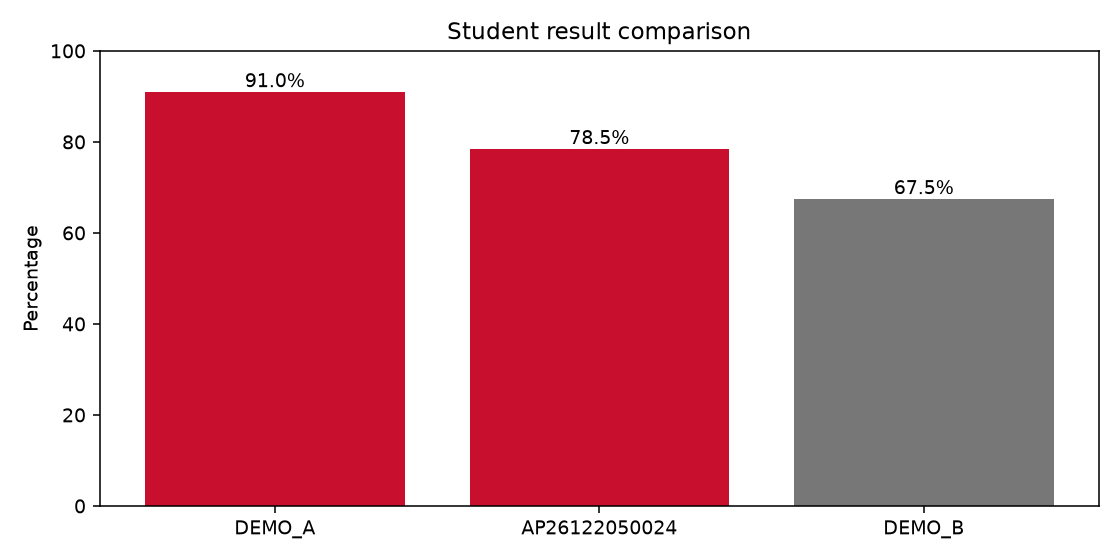

In [5]:
import matplotlib.pyplot as plt

names = [registration for registration, result in ranked]
percentages = [result[1] for registration, result in ranked]
colors = ["#C8102E" if result[3] == "Pass" else "#777777" for registration, result in ranked]

plt.figure(figsize=(8, 4))
bars = plt.bar(names, percentages, color=colors)
plt.bar_label(bars, fmt="%.1f%%")
plt.ylim(0, 100)
plt.ylabel("Percentage")
plt.title("Student result comparison")
plt.tight_layout()
plt.show()


### 6. Save the report
The website's **Export CSV** button saves the same result fields.

In [6]:
import csv

with open("student_results.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["Registration", "Total", "Percentage", "Grade", "Status"])
    for registration, result in results.items():
        writer.writerow([registration, result[0], f"{result[1]:.1f}", result[2], result[3]])

with open("student_results.csv", encoding="utf-8") as file:
    print(file.read())


Registration,Total,Percentage,Grade,Status
AP26122050024,314,78.5,B,Pass
DEMO_A,364,91.0,A+,Pass
DEMO_B,270,67.5,F,Fail

